In [1]:
source('../R/preamble.R')

pure = c('A', 'B', 'C', 'D', 'F')

dark_red = '#F24A14' #'#f29232'
light_red = '#ffd1a3'

In [2]:
# Growth rate time series
gr = rbind(
    read.tsv('../datasets/growth_curves/2025-03-23_AF_gamma/group_params_esch_AF_gamma.tsv') %>% mutate(set = 'AF'),
    #read.tsv('../25-02-27 Esch AF alpha, beta/Growth curves/group_params_esch_AF_alpha.tsv') %>% mutate(set = 'AF'),
    read.tsv('../datasets/growth_curves/2025-04-05_BC_alpha/group_params_BC_alpha.tsv') %>% mutate(set = 'BC', sample = ''),
    read.tsv('../datasets/growth_curves/2025-04-15_DE_alpha/group_params_esch_DE_alpha.tsv') %>% mutate(set = 'DE', sample = '')
    )

In [3]:
# Attribute wild-types
gr_wt_1 = gr %>% filter(strain == 'WT') %>% mutate(strain2 = substr(set, 1, 1))
gr_wt_2 = gr %>% filter(strain == 'WT') %>% mutate(strain2 = substr(set, 2, 2))
gr_no_wt = gr %>% filter(strain != 'WT') %>% mutate(strain2 = strain)


gru = rbind(gr_wt_1, gr_wt_2, gr_no_wt)

cultures = c('A', 'B', 'C', 'D', 'F')

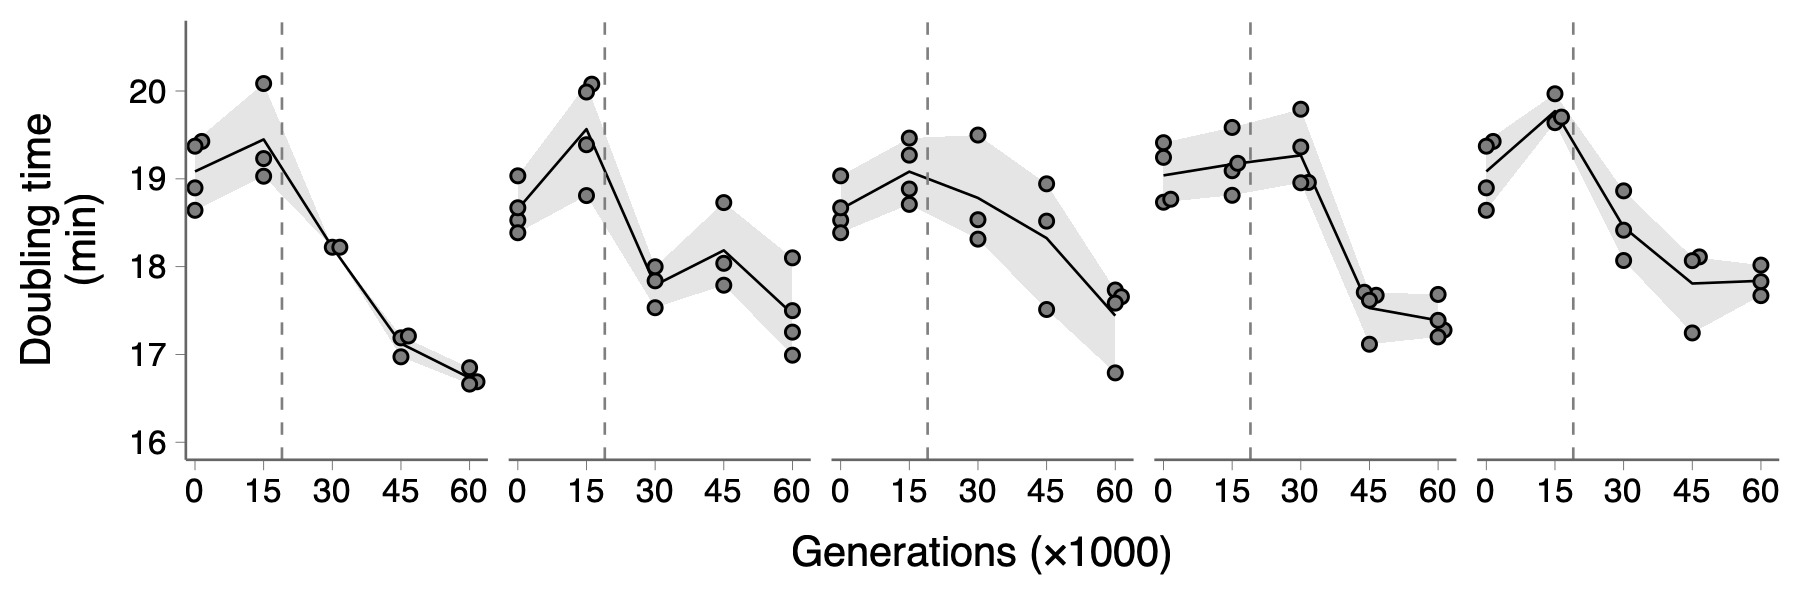

In [4]:
size(2, 6)

lwd = 0.3
ymin = 2.8
ymax = 3.7
eb_width = 2
stroke = 0.5
cex = 2.5

# Strain labels
strain_labels = data.frame(
    strain2 = c('A', 'B', 'C', 'D', 'F'),
    tau = 60 / (ymin + 0.1), gen = 24, strain = '' # xy coords on plot
    )

contrast = b

doubling_times_raw =

gru %>% 
    filter(strain2 %in% cultures) %>% 

ggplot() + 
    aes(x = gen * 2.5, 
        y = (tau),
        group = strain2) +

    scale_y_continuous(limits = c(15.8, 20.8), expand=c(0,0)) +
    scale_x_continuous(limits = c(-eb_width, 60+eb_width*2), breaks = seq(0,60,15), expand = c(0,0)) +

    scale_fill_manual(values = c(pal[1], w)) +

    facet_grid(~paste('Lineage', strain2)) +

    stat_summary(geom = 'ribbon', fun.min = min, fun.max = max, alpha = 0.1, fill = contrast, col = NA) +
    stat_summary(geom = 'line', fun = mean, lwd = 0.3, col = contrast) +

    geom_beeswarm(cex = cex, size = 1.25, pch = 21, stroke = stroke, col = contrast, fill = 'grey50') +
    #geom_point(pch = 21, stroke = 1.5*0.8 * lwd, size = 1.5, fill = w, col = b) +

    # Change in transfer time
    geom_vline(xintercept = 19, lwd = lwd, lty = 2, col = 'grey50') +

    # Inline strain labels
    # geom_text(data = strain_labels, aes(label = strain2), fontface = 'bold', col = 'grey10', size = 6, vjust = 0, hjust = 1) +

    theme(
        panel.grid = eb,
        strip.text = eb # lineage titles are drawn on the adhesion panel (top of Fig. 1)
    ) +

    #theme(axis.title.y = element_text(angle = 0, hjust = 0.5, vjust = 0.5)) +
    labs(x = 'Generations (×1000)', y = 'Doubling time\n(min)')


doubling_times_raw
saveRDS(doubling_times_raw, 'panels/doubling_times.rds')

In [5]:
# FimS data
fims_plotting_data = read.tsv('../datasets/adhesion/fim_switch/fims_plotting_data.tsv')

library(colorspace)

lighten <- function(color, factor = 0.5) {
    rgb_col <- col2rgb(color)
    rgb_col <- rgb_col + (255 - rgb_col) * factor
    rgb(rgb_col[1], rgb_col[2], rgb_col[3], maxColorValue = 255)
}

manual_colors = c(
    'ON_None' = lighten(dark_red, 0.4),
    'ON_C453T' = lighten(dark_red, 0.2),
    'ON_-461C' = lighten(dark_red, 0),
    
    'OFF_None' = lighten(pal[1], 0.4),
    'OFF_G160A' = lighten(pal[1], 0.1),
    'OFF_-155G, -461C' = lighten(pal[1], 0)
    )

In [6]:
# Make placeholder rows for the ancestor (which started in OFF position)
starting_point = 
    fims_plotting_data %>%
    filter(gen == 1) %>%
    mutate(x = 0, y = ifelse(geno == 'OFF_None', 1, 0))

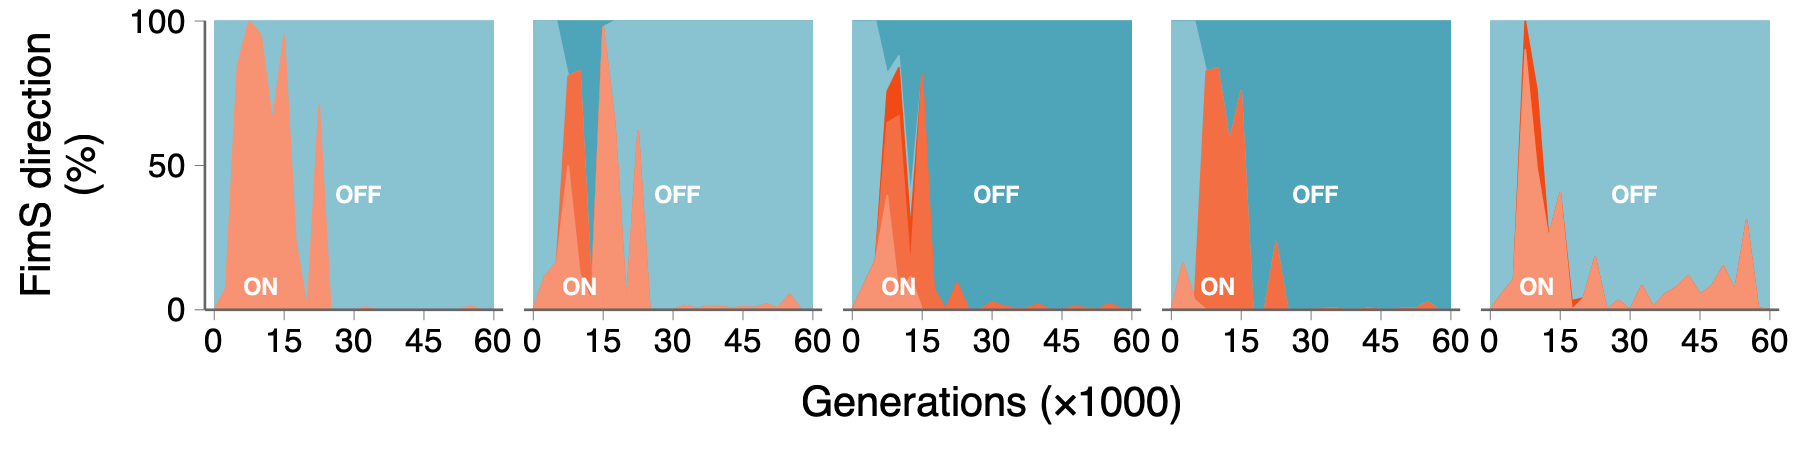

In [7]:
#pops = c('A', 'B', 'C', 'D', 'F')
size(4, 4)

eb_width = 2
label_size = 2

fims_plot =

fims_plotting_data %>% 
    bind_rows(starting_point) %>% 
    filter(pop %in% pure) %>% 

ggplot() + aes(x, y * 100, fill = geno, col = geno, group = geno) + nl +

    #facet_wrap(~pop) +
    facet_grid(~pop) +

    scale_x_continuous(limits = c(-eb_width, 60+eb_width), breaks = seq(0,60,15), expand = c(0,0)) +
    scale_y_continuous(limits = c(0, 100.1), breaks = 100*seq(0, 1, 0.5), expand = c(0,0)) +

    scale_fill_manual(values = manual_colors) +
    scale_color_manual(values = manual_colors) +

    geom_area(lwd = 0.2) +
    # geom_area_pattern(
    #     lwd = 0.2, pattern_alpha = 0.2, pattern_spacing = 0.04, pattern_density = 0.02,
    #     col = grey,
    #     aes(pattern = grepl('None', geno)), 
    # ) +
    # scale_pattern_discrete(choices = c('stripe', 'none')) +

    theme(
        strip.text = eb,
        panel.grid.major = eb,
        #axis.text.x = eb, axis.ticks.x = eb
    ) +

    # geom_line(
    #     data = sample_to_fraction %>% filter(orientation == 'ON', pop %in% pops, gen != 9),
    #     aes(x = gen * 2.5, y = freq_orientation, group = pop, fill = pop),
    #     col = 'grey20', lwd = 0.4
    #     ) +

    # geom_text(
    #     aes(group = T, fill = T, col = T, label = l), 
    #     fill = b, col = 'grey20', size = 2.5, fontface = 'bold',
    #     data = plot_labels,
    # ) +

    annotate(
        geom = 'text', size = label_size, col = w, fontface = 'bold',
        x = 10, y = 8, label = 'ON'
    ) +
    annotate(
        geom = 'text', size = label_size, col = w, fontface = 'bold',
        x = 31, y = 40, label = 'OFF'
    ) +
    #geom_vline(xintercept = 19, lty = 2, lwd = 0.2) +

    labs(x = 'Generations (×1000)', y = 'FimS direction\n(%)')

size(1.5, 6)

fims_plot
saveRDS(fims_plot, 'panels/fims.rds')

# Stickiness



In [8]:
stickiness = read.tsv('../datasets/adhesion/stickiness/stickiness.tsv') %>% 
    select(name, strain, gen, v)

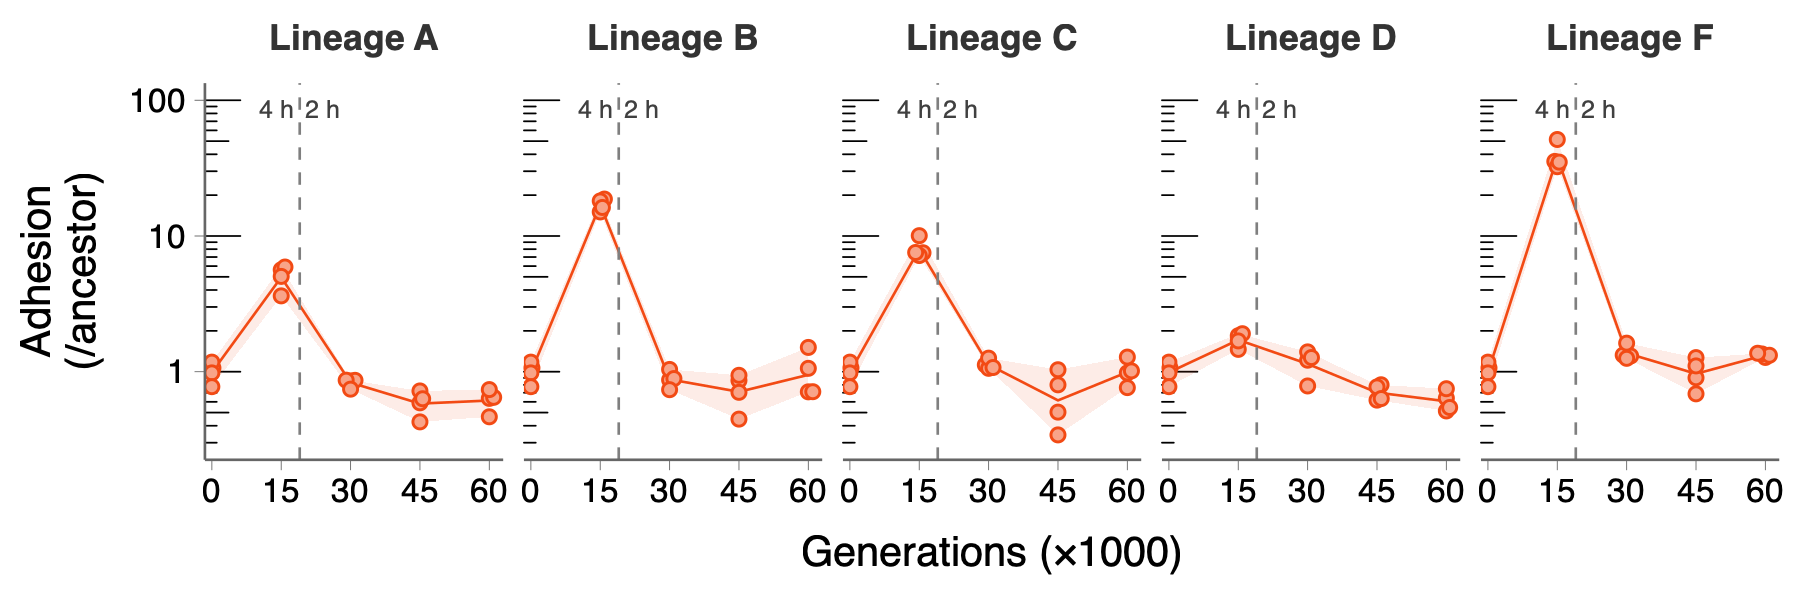

In [9]:
size(2, 6)

lwd = 0.3
ymin = 2.8
ymax = 3.7
eb_width = 1.5

contrast = dark_red #pal[5]
fill_col = lighten(dark_red, 0.5) #'#fa9284'

letters = tibble(strain = pure, gen = 23, v = 80)

stickiness_plot =

stickiness %>%        
    filter(strain %in% pure) %>% 

ggplot() + 
    aes(x = gen * 2.5, 
        y = v,
        group = strain) +

    scale_y_log10(limits = c(0.3, 100), breaks = 10^(0:2)) + logticks('l') +
    scale_x_continuous(limits = c(-eb_width, 60+eb_width*2), breaks = seq(0,60,15), expand = c(0,0)) +

    scale_fill_manual(values = c(pal[1], w)) +

    facet_grid(~paste('Lineage', strain)) +

    stat_summary(geom = 'ribbon', fun.min = min, fun.max = max, alpha = 0.1, fill = contrast, col = NA) +
    stat_summary(geom = 'line', fun = mean, lwd = 0.3, col = contrast) +

    geom_beeswarm(cex = 1.5, size = 1.25, pch = 21, stroke = stroke, col = contrast, fill = fill_col) +

    # Change in transfer time
    geom_vline(xintercept = 19, lwd = lwd, lty = 2, col = 'grey50') +
    annotate('text', x = 19 - 1.2, y = 100, label = '4 h', hjust = 1, vjust = 1, size = 6 / .pt, col = '#404040') +
    annotate('text', x = 19 + 1.2, y = 100, label = '2 h', hjust = 0, vjust = 1, size = 6 / .pt, col = '#404040') +

    # Inline strain labels
    # geom_text(
    #     data = letters,
    #     aes(label = strain), 
    #     fontface = 'bold', col = 'grey30', size = 4, vjust = 1, hjust = 1
    # ) +

    theme(
        panel.grid = eb,
        strip.text = element_text(size=8.5, face='bold', color='grey20', margin=margin(0,0,7,0)),
        #strip.text = element_text(size=8, face='bold', color='grey20', margin=margin(0,0,7,0))
    ) +

    #theme(axis.title.y = element_text(angle = 0, hjust = 0.5, vjust = 0.5)) +
    labs(x = 'Generations (×1000)', y = 'Adhesion\n(/ancestor)')

stickiness_plot
saveRDS(stickiness_plot, 'panels/stickiness.rds')